<a href="https://colab.research.google.com/github/Aftab-Ali786/dog_breed_identification/blob/main/dog_vision.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 🐶End-to-End multi-class Dog brid classificstion
this notebook builts an end-to-end multi-class image
classifier using Tansorflow 2.0 and atansore flow hub.

## 1.Problem
identify the breed of the dog by giving the image of a dog.

when i am siting in the caffe and take the picture of a dog,
want to know what breed of the dog it is.  


## 2.Data
the data we're using is from kaggel's dog breed identification competition .

https://www.kaggel.com/c/dog-breed-identification/data
## 3.Evaluation
the evaluation is a file with prediction probabilites for each dog breed of each test image.

https://www.kaggel.com/c/dog-breed-identification/overview/evaluation

## 4. Features
some information about the data:
* we're dealing with image (unstructured data) so it's probably best we use deep learning/transfer learning.
* there is about 120 breeds of dogs (this means there 120 different classes ).
* there are arrount 10000+ image in the traning set(therse images have labels).
* there is around 10000+ images in the test set (these images have no labels,because we'll want to predect them )

In [ ]:
#unzip the uploaded data into google Drive
#!unzip "drive/My Drive/Dog vision/dog-breed-identification.zip" -d "drive/My Drive/Dog vision"

# Get work space ready
* import tansorflow 2.19.0
* import tensorflow Hub.
* make shure we re using GPU




In [ ]:
# import tansore flow in to colab
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"
import tensorflow as tf
import tensorflow_hub as hub
print("TF version:",tf.__version__)
print("TF.hub version:",hub.__version__)

# chect for GPU availability
print("GPU", "available(YESSSS!!!!!)" if tf.config.list_physical_devices("GPU") else "not available:()")

TF version: 2.20.0
TF.hub version: 0.16.1
GPU available(YESSSS!!!!!)


## Geting our data ready (Tuning into tensors)

with all mechain learning model our data has to be in the numrical foramte.so thats what we'll be doing first.(The numarical representations).

let's start by accessing our data and checkout the label


In [ ]:
# check out the labels of our data
import pandas as pd
labels_csv = pd.read_csv("/content/drive/My Drive/Dog Vision/labels.csv")
print(labels_csv.describe())
print(labels_csv.head())

                                      id               breed
count                              10222               10222
unique                             10222                 120
top     fff43b07992508bc822f33d8ffd902ae  scottish_deerhound
freq                                   1                 126
                                 id             breed
0  000bec180eb18c7604dcecc8fe0dba07       boston_bull
1  001513dfcb2ffafc82cccf4d8bbaba97             dingo
2  001cdf01b096e06d78e9e5112d419397          pekinese
3  00214f311d5d2247d5dfe4fe24b2303d          bluetick
4  0021f9ceb3235effd7fcde7f7538ed62  golden_retriever


<Axes: xlabel='breed'>

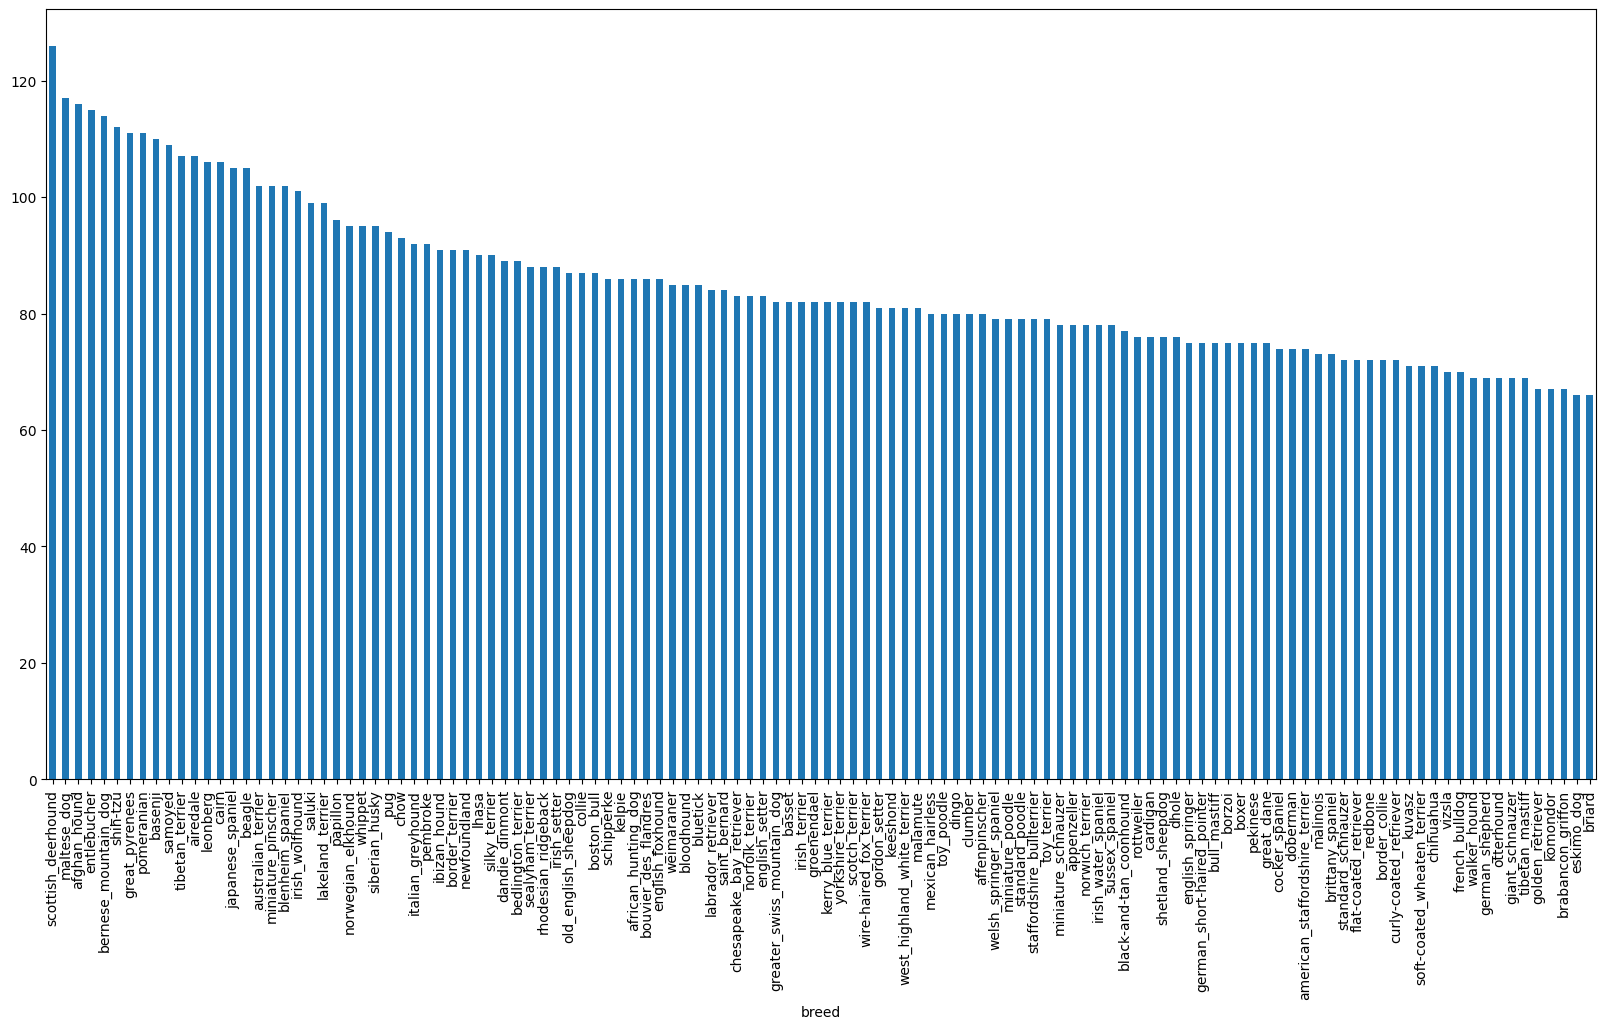

In [ ]:
# How many images are there of each breed?
labels_csv["breed"].value_counts().plot.bar(figsize=(20 ,10))

In [ ]:
labels_csv.head()

,id,breed
0,000bec180eb18c7604dcecc8fe0dba07,boston_bull
1,001513dfcb2ffafc82cccf4d8bbaba97,dingo
2,001cdf01b096e06d78e9e5112d419397,pekinese
3,00214f311d5d2247d5dfe4fe24b2303d,bluetick
4,0021f9ceb3235effd7fcde7f7538ed62,golden_retriever


In [ ]:
# whats median number of images per class?
labels_csv["breed"].value_counts().median()

82.0

In [ ]:
# How many images are there of each breed
labels_csv["breed"].value_counts()

,count
breed,
scottish_deerhound,126
maltese_dog,117
afghan_hound,116
entlebucher,115
bernese_mountain_dog,114
...,...
golden_retriever,67
komondor,67
brabancon_griffon,67


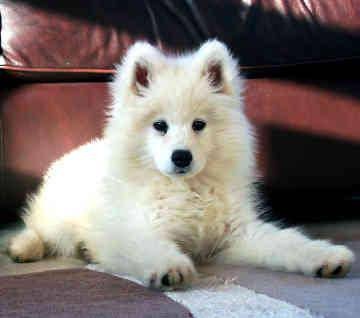

In [ ]:
# lets view an image
from IPython.display import Image
Image("/content/drive/My Drive/Dog Vision/test/002c58d413a521ae8d1a5daeb35fc803.jpg")

### getting images and there leables
Let's get a list of all our images with there pathnames.

In [ ]:
labels_csv.head()

,id,breed
0,000bec180eb18c7604dcecc8fe0dba07,boston_bull
1,001513dfcb2ffafc82cccf4d8bbaba97,dingo
2,001cdf01b096e06d78e9e5112d419397,pekinese
3,00214f311d5d2247d5dfe4fe24b2303d,bluetick
4,0021f9ceb3235effd7fcde7f7538ed62,golden_retriever


In [ ]:
# create path name from image ID's
filename = ["/content/drive/My Drive/Dog Vision/train/"+ fname + ".jpg" for fname in labels_csv["id"]]
# check first ten
filename[:10]

['/content/drive/My Drive/Dog Vision/train/000bec180eb18c7604dcecc8fe0dba07.jpg',
 '/content/drive/My Drive/Dog Vision/train/001513dfcb2ffafc82cccf4d8bbaba97.jpg',
 '/content/drive/My Drive/Dog Vision/train/001cdf01b096e06d78e9e5112d419397.jpg',
 '/content/drive/My Drive/Dog Vision/train/00214f311d5d2247d5dfe4fe24b2303d.jpg',
 '/content/drive/My Drive/Dog Vision/train/0021f9ceb3235effd7fcde7f7538ed62.jpg',
 '/content/drive/My Drive/Dog Vision/train/002211c81b498ef88e1b40b9abf84e1d.jpg',
 '/content/drive/My Drive/Dog Vision/train/00290d3e1fdd27226ba27a8ce248ce85.jpg',
 '/content/drive/My Drive/Dog Vision/train/002a283a315af96eaea0e28e7163b21b.jpg',
 '/content/drive/My Drive/Dog Vision/train/003df8b8a8b05244b1d920bb6cf451f9.jpg',
 '/content/drive/My Drive/Dog Vision/train/0042188c895a2f14ef64a918ed9c7b64.jpg']

In [ ]:
# check whether the file name match with the actual image files
import os
if len(os.listdir("/content/drive/My Drive/Dog Vision/train/"))== len(filename):
  print("Filename match actual amount of files !!! proceed.")
else:
    print("file name do not match with the actuel  amount of files, check the target directory ")

Filename match actual amount of files !!! proceed.


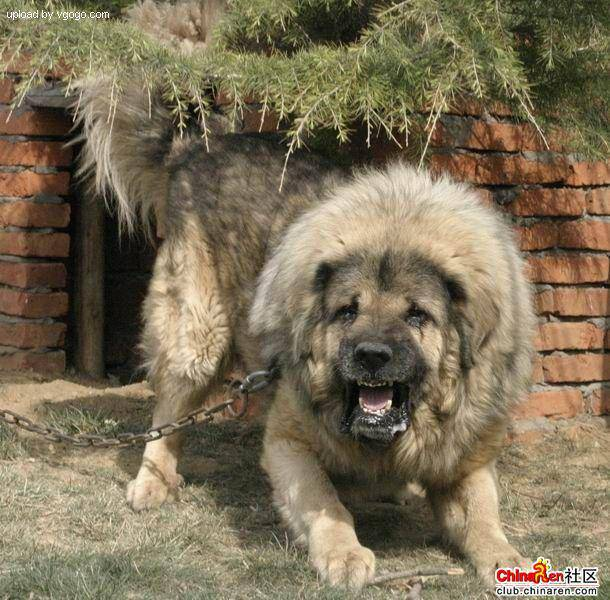

In [ ]:
# one check image
Image(filename[9000])

In [ ]:
labels_csv["breed"][9000]

'tibetan_mastiff'

# since we've now got our training image filepath in a list,let's prepare our labels.

In [ ]:
import numpy as np
labels = labels_csv["breed"]
labels = np.array(labels)
labels

array(['boston_bull', 'dingo', 'pekinese', ..., 'airedale',
       'miniature_pinscher', 'chesapeake_bay_retriever'], dtype=object)

In [ ]:
len(labels)

10222

In [ ]:
# see if number of labels matches the number of filename
if len(labels) == len(filename):
  print("Number of labels matches number of filenames !")
else:
  print("Number of labels does not matche with the  filename , checkthe dierectory ")

Number of labels matches number of filenames !


In [ ]:
# find the unique labels values
unique_breed = np.unique(labels)
unique_breed[:10]

array(['affenpinscher', 'afghan_hound', 'african_hunting_dog', 'airedale',
       'american_staffordshire_terrier', 'appenzeller',
       'australian_terrier', 'basenji', 'basset', 'beagle'], dtype=object)

In [ ]:
# turrn a single lable into an array of booleans
print(labels[0])
labels[0] ==unique_breed

boston_bull


array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False,  True, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False])

In [ ]:
# turn every  the labels into a boolean array
boolean_labels = [labels == unique_breed for labels in labels]
boolean_labels[:2]

[array([False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False,  True, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False]),
 array([False, False, False, False, False, Fal

In [ ]:
len(boolean_labels)

10222

In [ ]:
#Example: Turning Boolean array into integers
print(labels[0]) #origianl label
print(np.where(unique_breed == labels[0])) # index where lablel occurs
print(boolean_labels[0].argmax())# index where label occur in boolean array
print(boolean_labels[0].astype(int))#there will be 1 where the sample lable occurs

boston_bull
(array([19]),)
19
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0]


In [ ]:
print(labels[2])
print(boolean_labels[2].astype(int))

pekinese
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0]


### Cretae your own velidation set
since the data from kalggle dosn't come with velidation set, we're going to create own.

In [ ]:
# setup x & y variables
x = filename
y = boolean_labels

In [ ]:
len(filename)

10222

We're going to start off experimenting with ~1000 images and increase as needed.

In [ ]:
# @title Set number of images to use for experimenting
NUM_IMAGES = 1000  # @param {type:"slider", min:1000, max:10000, step:1000}
print("Number of images selected:", NUM_IMAGES)


Number of images selected: 1000


In [ ]:
# Let's split our data into train and validtaion sets
from sklearn.model_selection import train_test_split
#split them into training and validation of total size NUM_IMAGES
x_train ,x_val,y_train,y_val = train_test_split(x[:NUM_IMAGES],
                                               y[:NUM_IMAGES],
                                               test_size =0.2,
                                               random_state=42)
len(x_train),len(y_train),len(x_val),len(y_val)

(800, 800, 200, 200)

In [ ]:
# Let's have a geez at the training data
x_train[:5],y_train[:2]

(['/content/drive/My Drive/Dog Vision/train/00bee065dcec471f26394855c5c2f3de.jpg',
  '/content/drive/My Drive/Dog Vision/train/0d2f9e12a2611d911d91a339074c8154.jpg',
  '/content/drive/My Drive/Dog Vision/train/1108e48ce3e2d7d7fb527ae6e40ab486.jpg',
  '/content/drive/My Drive/Dog Vision/train/0dc3196b4213a2733d7f4bdcd41699d3.jpg',
  '/content/drive/My Drive/Dog Vision/train/146fbfac6b5b1f0de83a5d0c1b473377.jpg'],
 [array([False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False,  True,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
        

### Preprossing Images(turning images into Tensore )
To preprocess our image into Tansore we're going to write a function which does a few things.
1. Take an image filepath as input
2. Use Tansore flow to read the file and save it a varibal`Image`
3. Turn our `image`(a jpg) into tansors
4. Normalize our image(convert color channel value from 0-255 to 0-1)
5. resize the `Image` to be the shape of (224,224)
6. Return the modified `Image `

Before we do, lets' see what importig an image look like

In [ ]:
# Conver the image into numpy array
from matplotlib.pyplot import imread
image = imread(filename[42])
image.shape

(257, 350, 3)

In [ ]:
tf.constant(image)[:2]

<tf.Tensor: shape=(2, 350, 3), dtype=uint8, numpy=
array([[[ 89, 137,  89],
        [ 76, 124,  76],
        [ 63, 111,  61],
        ...,
        [ 77, 133,  86],
        [ 76, 134,  86],
        [ 76, 134,  86]],

       [[ 72, 119,  75],
        [ 67, 114,  68],
        [ 63, 110,  64],
        ...,
        [ 75, 131,  84],
        [ 74, 132,  84],
        [ 74, 132,  84]]], dtype=uint8)>

In [ ]:
# Define the image size
IMG_SIZE = 224

# create a function for preprocesig image
def process_image(image_path, img_size =IMG_SIZE):
  """
  Takes an image file path and turns the image into a Tensor.
  """
  # Read in an image file
  image = tf.io.read_file(image_path)
  # Turn the jpeg image into  numarical Tansor with 3 colour channels(Read, green,blue)
  image =tf.image.decode_jpeg(image , channels = 3)
  # conver the clolour vlaue from 0-255 to 0-1 value
  image = tf.image.convert_image_dtype(image, tf.float32)
  # re'size the image to our desired value(224,224)
  image = tf.image .resize (image,size=[IMG_SIZE ,IMG_SIZE])
  return image

## Turning our data into batches
Why turn on our data batches?
Let's say you're trying to process 10000+ images in one go...they all might not fit into memory.

so that's why wedo about 32 (things is the batch size) images at time (you can manually adjust batches if need to be  )

IN order to use the tensore flpw effectly ,we need our data in the form of tensore tuple which looklike this:(image,lable)

In [ ]:
def get_image_lable(image_path, label):
    """
    Takes an image file path and its associated label,
    processes the image, and returns a tuple (image, label).
    """
    image = process_image(image_path)
    return image, label


In [ ]:
# demo of above
(process_image(x[42], IMG_SIZE), y[42])


(<tf.Tensor: shape=(224, 224, 3), dtype=float32, numpy=
 array([[[0.3264178 , 0.5222886 , 0.3232816 ],
         [0.2537167 , 0.44366494, 0.24117757],
         [0.25699762, 0.4467087 , 0.23893751],
         ...,
         [0.29325107, 0.5189916 , 0.3215547 ],
         [0.29721776, 0.52466875, 0.33030328],
         [0.2948505 , 0.5223015 , 0.33406618]],
 
        [[0.25903144, 0.4537807 , 0.27294815],
         [0.24375686, 0.4407019 , 0.2554778 ],
         [0.2838985 , 0.47213382, 0.28298813],
         ...,
         [0.2785345 , 0.5027992 , 0.31004712],
         [0.28428748, 0.5108719 , 0.32523635],
         [0.28821915, 0.5148036 , 0.32916805]],
 
        [[0.20941195, 0.40692952, 0.25792548],
         [0.24045378, 0.43900946, 0.2868911 ],
         [0.29001117, 0.47937486, 0.32247734],
         ...,
         [0.26074055, 0.48414773, 0.30125174],
         [0.27101526, 0.49454468, 0.32096273],
         [0.27939945, 0.5029289 , 0.32934693]],
 
        ...,
 
        [[0.00634795, 0.03442048

Now we've got a way to turn our data  into tuples of tensors in the form:`(images,labels)`, let me make a function to turn all our data`(x & y)` into batches!

In [ ]:
# Define the batch size
BATCH_SIZE = 32

# Function to turn data into batches
def create_data_batches(x, y=None, batch_size=BATCH_SIZE, valid_data=False, test_data=False):
    """
    Creates batches of data out of image (x) and label (y) pairs.
    Shuffles the data if it's training data but not if it's validation data.
    Also accepts test data as input (no labels).
    """
    if test_data:
        print("Creating test data batches...")
        data = tf.data.Dataset.from_tensor_slices(tf.constant(x))  # only filepaths
        data_batch = data.map(lambda img: process_image(img)).batch(batch_size).prefetch(tf.data.AUTOTUNE)
        return data_batch

    elif valid_data:
        print("Creating validation data batches...")
        data = tf.data.Dataset.from_tensor_slices((tf.constant(x), tf.constant(y)))
        data_batch = data.map(get_image_lable).batch(batch_size).prefetch(tf.data.AUTOTUNE)
        return data_batch

    else:
        print("Creating training data batches...")
        data = tf.data.Dataset.from_tensor_slices((tf.constant(x), tf.constant(y)))
        data = data.shuffle(buffer_size=len(x))  # shuffle only training data
        data = data.map(get_image_lable)
        data_batch = data.batch(batch_size).prefetch(tf.data.AUTOTUNE)
        return data_batch


In [ ]:
# Create training and validation data batches
train_data = create_data_batches(x_train, y_train)
val_data = create_data_batches(x_val, y_val, valid_data=True)


Creating training data batches...
Creating validation data batches...


In [ ]:
# check out the different attributes of our data batches
train_data.element_spec,val_data.element_spec

((TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None),
  TensorSpec(shape=(None, 120), dtype=tf.bool, name=None)),
 (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None),
  TensorSpec(shape=(None, 120), dtype=tf.bool, name=None)))

## Visulizing  data batches
our data in now in batches, however,these can be a little can be little hard to undrstsnd /comprehend,lets visulise the

In [ ]:
import matplotlib.pyplot as plt
# Create a function for viewing image in data batch
def show_25_images(images,labels):
  """
  Displays a plot of 25 images and their labels from a data batch.
  """
  #Setup the figure
  plt.figure(figsize = (10,10))
  # Loop through 25 (for displaying 25 images)
  for i in range(25):
    # Create subplots(5 rows, 5 columns)
    ax = plt.subplot(5,5, i+1)
    # Display an image
    plt.imshow(images[i])
    # Add the image label as a title
    plt.title(unique_breed[labels[i].argmax()])
    #turn the grid line off
    #plt.axis("off")


In [ ]:
train_data

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 120), dtype=tf.bool, name=None))>

In [ ]:
train_images, train_labels =next(train_data.as_numpy_iterator())

In [ ]:
unique_breed[y[0].argmax()]

'boston_bull'

In [ ]:
unique_breed

array(['affenpinscher', 'afghan_hound', 'african_hunting_dog', 'airedale',
       'american_staffordshire_terrier', 'appenzeller',
       'australian_terrier', 'basenji', 'basset', 'beagle',
       'bedlington_terrier', 'bernese_mountain_dog',
       'black-and-tan_coonhound', 'blenheim_spaniel', 'bloodhound',
       'bluetick', 'border_collie', 'border_terrier', 'borzoi',
       'boston_bull', 'bouvier_des_flandres', 'boxer',
       'brabancon_griffon', 'briard', 'brittany_spaniel', 'bull_mastiff',
       'cairn', 'cardigan', 'chesapeake_bay_retriever', 'chihuahua',
       'chow', 'clumber', 'cocker_spaniel', 'collie',
       'curly-coated_retriever', 'dandie_dinmont', 'dhole', 'dingo',
       'doberman', 'english_foxhound', 'english_setter',
       'english_springer', 'entlebucher', 'eskimo_dog',
       'flat-coated_retriever', 'french_bulldog', 'german_shepherd',
       'german_short-haired_pointer', 'giant_schnauzer',
       'golden_retriever', 'gordon_setter', 'great_dane',
      

In [ ]:
train_data

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 120), dtype=tf.bool, name=None))>

In [ ]:
train_images, train_labels = next(train_data.as_numpy_iterator())
len(train_images),len(train_labels)

(32, 32)

## Building a model
Before  we  bulid a model,there are few things we need to define :


*  The input shape (our images shape, in the form of Tensors) to our model.
* the output shape (image labels, in the form of Tensors)of our model.
* the URL of the model we want to use.




In [ ]:
# Image size
IMG_SIZE = 224

# Input shape (batch, height, width, channels)
INPUT_SHAPE = (None, IMG_SIZE, IMG_SIZE, 3)

# Output shape (number of classes)
OUTPUT_SHAPE = len(unique_breed)

# Correct TF Hub feature extractor
MODEL_URL = "https://tfhub.dev/google/imagenet/mobilenet_v2_100_224/feature_vector/5"


Now we got our input output and model realy to go. Let's put them togather into a Keras deep learning model!
Knowing this,let's create a function which:


*   Takes the input shape, output shape and the model we chose as a parameters.
*  Define the layers in a kerse model in a sequential fashion(do this first then this then that).
* Compilers the model(Says it should be equivalend and improved).
* Builds the model(tells the model the input shape it'll be getting).
* Returns the model.

All of these steps are found here: https://www.tensorflow.org/guide/keras



In [ ]:
import tensorflow as tf
import tensorflow_hub as hub
# Force the use of the legacy Keras path if you're on Keras 3
import tf_keras

def create_model(
    input_shape=(224, 224, 3),
    output_shape=OUTPUT_SHAPE,
    model_url=MODEL_URL
):
    # Use tf_keras specifically to avoid the symbolic tensor error
    inputs = tf_keras.Input(shape=input_shape)

    x = hub.KerasLayer(
        model_url,
        trainable=False
    )(inputs)

    outputs = tf_keras.layers.Dense(output_shape, activation="softmax")(x)

    model = tf_keras.Model(inputs, outputs)

    model.compile(
        optimizer=tf_keras.optimizers.Adam(),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    # Note: model.build is usually redundant here since you used the Functional API
    # but if you keep it, use the input_shape tuple.
    model.build((None, *input_shape))

    return model

In [ ]:
model = create_model()
model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 keras_layer (KerasLayer)    (None, 1280)              2257984   
                                                                 
 dense (Dense)               (None, 120)               153720    
                                                                 
Total params: 2411704 (9.20 MB)
Trainable params: 153720 (600.47 KB)
Non-trainable params: 2257984 (8.61 MB)
_________________________________________________________________


## Creating callbacks

Callbacks are the functions a model can use during training to do such things as save its progress, check its progress or stop training early if a model stops improvig.

we create two callback one for transBord which helps track our models progress and another for early stopping which prevents our model from training for too long.

### TranserBoard callback

To setup transorBoard callback we need to do 3 things :

To setup a tensorBoard callback, we need to do 3 things
1.   Load the tensorebaoard nootbook extention
2.   Create a tensoreBoard callback which is able to save logs to a directory and pass it to the our model's `fit()` function.
3. visulize our model traning logs with the %tensoreboard magic function (we'll do this after model training ).



In [ ]:
# Load tensoreboard notebook extension
%load_ext tensorboard

In [ ]:
import os
import datetime
import tensorflow as tf

# create a function to build a TensorBoard callback
def create_tensorboard_callback():
    logdir = os.path.join(
        "/content/drive/My Drive/Dog Vision/logs",
        datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
    )

    return tf_keras.callbacks.TensorBoard(log_dir=logdir)


  ### Early stoping callback

  Eraly stopping helps stop our model from over model from overfiting by stopping training if certain evaluation metric stops improving .
  
  https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/EarlyStopping



In [ ]:
# Create early stopping callback
early_stopping = tf_keras.callbacks.EarlyStopping(monitor="val_accuracy",
                                                  patience=3)

## Training a model(on subset of data)
our first model is only going train on 1000 images,to make sure everything is working.

In [ ]:
 NUM_EPOCHS = 100 #@param {type:"slider",min:10,max:100, step:10 }

In [ ]:
# check to make sure we're still running on a GPU
print("GPU","availbale (YESSSSS!!!!!)" if tf.config.list_physical_devices("GPU") else "not availabel :(")

GPU availbale (YESSSSS!!!!!)


Let's create a function which trains a model.


*   Create a model using `create_model()`
*   setup a TensoreBoard callback using `create_tensorboard_callback()`
*  call the `fit()` function on our model passing it the training data,
number of epochs to train for (`NUM_EPOCHS`) and the callbacks we'd like to use
* Return the model


In [ ]:
# Build a function to train and return a trained model
def train_model():
  """
  Trains a given model and returns the trained version.
  """
  # Create new TensorBoard session everytime we train a model
  tensorboard = create_tensorboard_callback()

  # fit the model to the data passing it the callbacks we created
  model.fit(x= train_data,
            epochs=NUM_EPOCHS,
            validation_data=val_data,
            validation_freq=1,
            callbacks=[tensorboard,early_stopping ])
  # Return the fitting model
  return model

In [ ]:
# fit the model to the data
model= train_model()

Epoch 1/100
25/25 [==============================] - 60s 2s/step - loss: 1.7216 - accuracy: 0.7312 - val_loss: 2.0742 - val_accuracy: 0.5450
Epoch 2/100
25/25 [==============================] - 3s 118ms/step - loss: 0.7209 - accuracy: 0.9413 - val_loss: 1.6245 - val_accuracy: 0.6500
Epoch 3/100
25/25 [==============================] - 5s 192ms/step - loss: 0.3735 - accuracy: 0.9837 - val_loss: 1.4162 - val_accuracy: 0.7000
Epoch 4/100
25/25 [==============================] - 3s 110ms/step - loss: 0.2315 - accuracy: 0.9950 - val_loss: 1.3406 - val_accuracy: 0.7150
Epoch 5/100
25/25 [==============================] - 5s 185ms/step - loss: 0.1654 - accuracy: 0.9975 - val_loss: 1.2780 - val_accuracy: 0.7250
Epoch 6/100
25/25 [==============================] - 3s 108ms/step - loss: 0.1249 - accuracy: 1.0000 - val_loss: 1.2429 - val_accuracy: 0.7100
Epoch 7/100
25/25 [==============================] - 3s 111ms/step - loss: 0.0987 - accuracy: 1.0000 - val_loss: 1.2257 - val_accuracy: 0.7350
E

### check the tensprBoard logs
The TransorBoard magic function (`%tensorboard `) will acess the log directory we created earlier and veusilize  its contacts.

In [ ]:
%tensorboard --logdir "/content/drive/My Drive/Dog Vision/logs"


<IPython.core.display.Javascript object>

## Making and evaluating prediction using a trained model

In [ ]:
# Make pridctions on the validation data (not used to train on )
predictions = model.predict(val_data, verbose=1)
predictions


7/7 [==============================] - 1s 94ms/step


array([[2.2630019e-03, 8.5340027e-04, 2.3508989e-04, ..., 3.0087298e-04,
        1.2176788e-04, 4.5633675e-03],
       [3.8733464e-03, 9.1439439e-03, 2.2743741e-02, ..., 2.5455753e-04,
        9.7213164e-03, 1.4813704e-05],
       [6.8340696e-06, 2.6988430e-04, 5.3502186e-05, ..., 1.8625399e-04,
        1.5308861e-04, 3.9176480e-04],
       ...,
       [5.6470693e-05, 4.1061116e-04, 4.2279353e-05, ..., 1.1667509e-05,
        7.4046562e-05, 1.8335230e-04],
       [5.6760840e-04, 3.0984764e-05, 2.8540081e-04, ..., 1.8935154e-05,
        2.4842220e-05, 2.0619510e-03],
       [2.8434659e-05, 8.0639120e-06, 2.1632640e-04, ..., 1.5511005e-03,
        5.5111462e-04, 2.5985099e-04]], dtype=float32)

In [ ]:
predictions.shape

(200, 120)

In [ ]:
# First prediction
index = 42
print(predictions[0])
print(f"Max value(probability of pridiction):{np.max(predictions[0])}")
print(f"sum: {np.sum(predictions[index])}")
print(f"Max index: {np.argmax(predictions[index])}")
print(f"predicted labels: {unique_breed[np.argmax(predictions[index])]}")


[2.26300186e-03 8.53400270e-04 2.35089887e-04 3.16132355e-04
 2.94298329e-03 2.07433732e-05 2.64728181e-02 1.37747789e-03
 2.04662007e-04 5.43082861e-05 6.35444652e-04 1.24977887e-04
 3.30355615e-05 4.63874385e-05 5.31879268e-05 2.08390731e-04
 3.54999975e-05 7.89497718e-02 6.67860077e-05 1.17645475e-04
 8.59701657e-04 7.03094760e-04 3.32655254e-05 1.44476478e-03
 3.41532032e-05 1.93522632e-04 1.48498267e-01 4.81505849e-04
 2.35693436e-03 4.95332351e-04 4.65339457e-04 2.23940983e-03
 3.24216177e-04 7.85404918e-05 4.12920890e-05 1.73978675e-02
 3.39345250e-04 5.17110224e-04 2.16615099e-05 2.38873417e-05
 2.33518804e-04 1.10424247e-04 6.51971714e-05 4.51883563e-04
 7.47609738e-05 1.14452711e-03 6.10801362e-05 8.88431561e-04
 1.69834692e-03 1.89982558e-04 2.70155251e-05 1.84702338e-04
 2.60852999e-03 7.65253353e-05 3.11706899e-05 2.00510913e-05
 2.05606513e-04 3.03991232e-03 3.72544491e-05 2.73679327e-02
 6.96295174e-04 2.89799063e-04 6.63251616e-04 1.47012121e-04
 1.66654092e-04 1.167971

In [ ]:
unique_breed[39]

'english_foxhound'

 Heaving the above functionality is great but we want to be able to do it at scale.
And it would be even better if we could see the image the image the pridection is being made on!

**Note:** Pridction probability are also known as confidence lavels.  

In [ ]:
#Turn pridiction probibability into their respective label (easier to understand)
def get_pred_label(prediction_probabilities):
  """
  Turns an array of pridiction probabilities into a label.
  """
  return unique_breed[np.argmax(prediction_probabilities)]

# Get a pridiction label based on array of prediction probabilities
pred_label = get_pred_label(predictions[81])
pred_label


'irish_setter'

Now since our validation data is still in a batch dataset, we'll have to unbeachify it to make prediction on the validation image and then compair those predictions to validation label(true labels).

In [ ]:
val_data

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 120), dtype=tf.bool, name=None))>

In [ ]:
# create a function to unbatch a batch dataset
def unbachify(data):
  """
  Take a batched dataset of (image, label) Tensors and return separate arrays ofimage and labels.
  """
  images= []
  labels= []
  # loop through unbatch the data
  for image, label in data.unbatch().as_numpy_iterator():
    images.append(image)
    labels.append(label)
  return images,labels

# unbatchfy the validation vale
val_images,val_labels = unbachify(val_data)
val_images[0], val_labels[0]

(array([[[0.29599646, 0.43284872, 0.3056691 ],
         [0.26635826, 0.32996926, 0.22846507],
         [0.31428418, 0.27701408, 0.22934894],
         ...,
         [0.77614343, 0.82320225, 0.8101595 ],
         [0.81291157, 0.8285351 , 0.8406944 ],
         [0.8209297 , 0.8263737 , 0.8423668 ]],
 
        [[0.2344871 , 0.31603682, 0.19543913],
         [0.3414841 , 0.36560842, 0.27241898],
         [0.45016077, 0.40117094, 0.33964607],
         ...,
         [0.7663987 , 0.8134138 , 0.81350833],
         [0.7304248 , 0.75012016, 0.76590735],
         [0.74518913, 0.76002574, 0.7830809 ]],
 
        [[0.30157745, 0.3082587 , 0.21018331],
         [0.2905954 , 0.27066195, 0.18401104],
         [0.4138316 , 0.36170745, 0.2964005 ],
         ...,
         [0.79871625, 0.8418535 , 0.8606443 ],
         [0.7957738 , 0.82859945, 0.8605655 ],
         [0.75181633, 0.77904975, 0.8155256 ]],
 
        ...,
 
        [[0.9746779 , 0.9878955 , 0.9342279 ],
         [0.99153054, 0.99772066, 0.94278

Now we've got ways to get:
* Prediction labels
* Validation labels(truth labels)
* Validatioon images

Let's make some function to make these all a bit more visaulize.

we'll create a function which:
* Takes an array of pridiction probalilities, an array of truth labels and the arrya of images and integers.
* Convert the pridiction probabilities to  a pridicted label.
* plot the pridicted label, its predicted probability, the truth label and the target image on a single plot .

In [ ]:
def plot_pred(prediction_probabilities, labels, images, n=1):
    """
    View the prediction, ground truth and image for sample n
    """

    pred_prob = prediction_probabilities[n]
    true_label = labels[n]
    image = images[n]

    # Convert probabilities to predicted class index
    pred_label = np.argmax(pred_prob)

    # Convert true label if one-hot encoded
    if len(true_label.shape) > 0:
        true_label = np.argmax(true_label)

    # Plot image
    plt.imshow(image)
    plt.xticks([])
    plt.yticks([])

    confidence = np.max(pred_prob) * 100

    # Color based on correctness
    if pred_label == true_label:
        color = "green"
    else:
        color = "red"

    plt.title(
        f"Pred: {pred_label} | Conf: {confidence:.2f}% | True: {true_label}",
        color=color
    )

    plt.show()

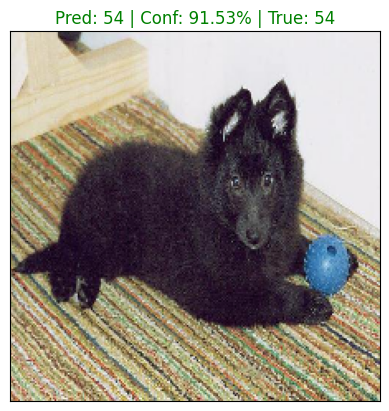

In [ ]:
plot_pred(
    prediction_probabilities=predictions,
    labels=val_labels,
    images=val_images,
    n=77
)

Now we've got one function to visulize our models top prediction.let's make another to view our models top 10 predictions.
this function will:
* Take an input of predicilities array and a ground truth array and an integer
* find the prediction using `get_pred_label()`

* Find the top 10:
  * prdiction probabilities indexes
  * Prediction probability values
  * prediction labels
* Plot the top 10 prediction probability value and labels, coloring the truth labael green

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_pred_conf(prediction_probabilities, labels, n=1):
    """
    Plot top 10 highest prediction confidences along with the true label for sample n.
    """

    pred_prob = prediction_probabilities[n]
    true_label = labels[n]

    # If label is one-hot encoded
    if len(true_label.shape) > 0:
        true_label = np.argmax(true_label)

    # Get predicted label index
    pred_label = np.argmax(pred_prob)

    # Top 10 prediction indexes
    top_10_pred_indexes = pred_prob.argsort()[-10:][::-1]

    # Top 10 values
    top_10_pred_values = pred_prob[top_10_pred_indexes]

    # Top 10 labels
    top_10_pred_labels = unique_breed[top_10_pred_indexes]

    # Plot
    plt.figure(figsize=(10, 6))
    bars = plt.bar(np.arange(len(top_10_pred_labels)), top_10_pred_values)

    plt.xticks(
        np.arange(len(top_10_pred_labels)),
        top_10_pred_labels,
        rotation=90
    )

    # Highlight true label in green if present
    if true_label in top_10_pred_indexes:
        index = list(top_10_pred_indexes).index(true_label)
        bars[index].set_color("green")

    # Highlight predicted label in red
    if pred_label in top_10_pred_indexes:
        index = list(top_10_pred_indexes).index(pred_label)
        bars[index].set_color("red")

    plt.ylabel("Prediction Confidence")
    plt.title("Top 10 Prediction Confidences")

    plt.show()


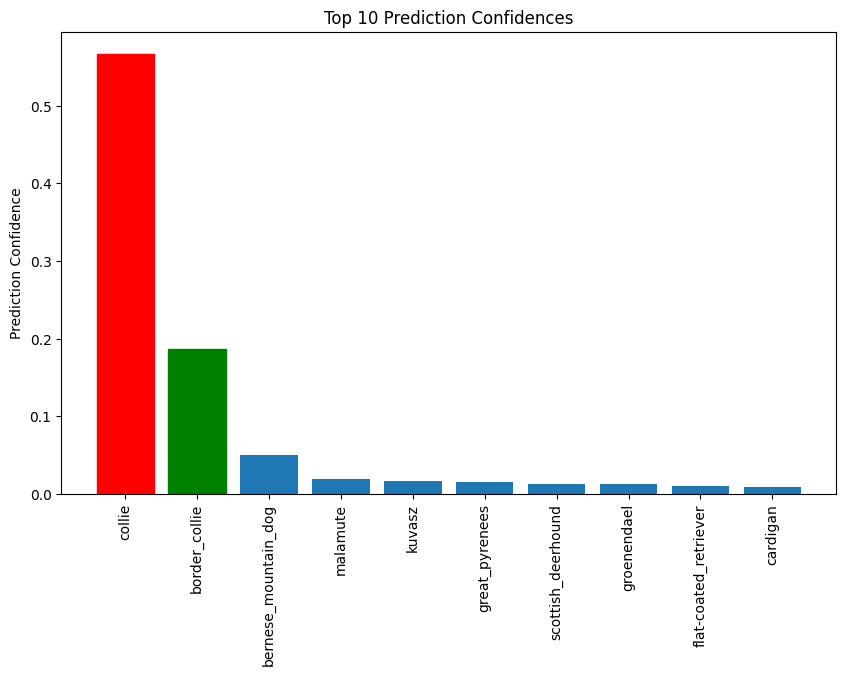

In [ ]:
plot_pred_conf(prediction_probabilities=predictions,
               labels=val_labels,
               n=9)


now we'll got some function to help us visulize our predictions and evaluate our model, lets checkout

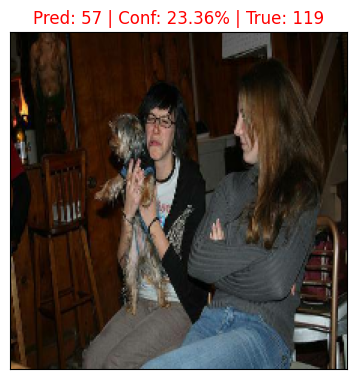

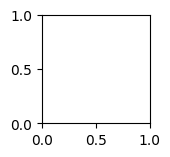

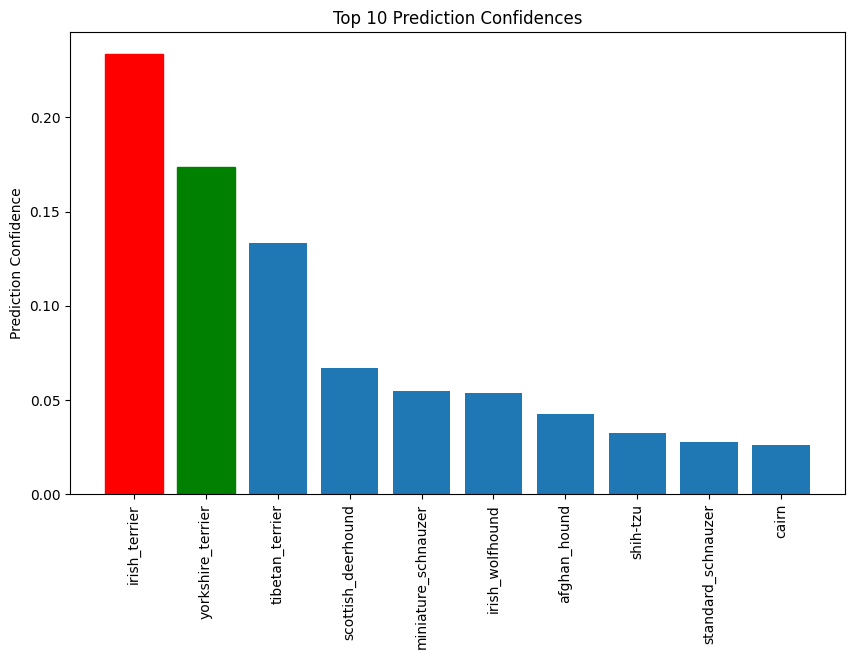

<Figure size 640x480 with 0 Axes>

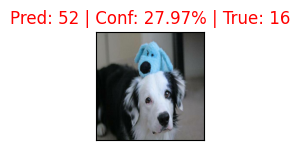

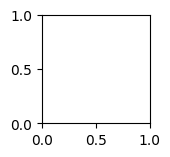

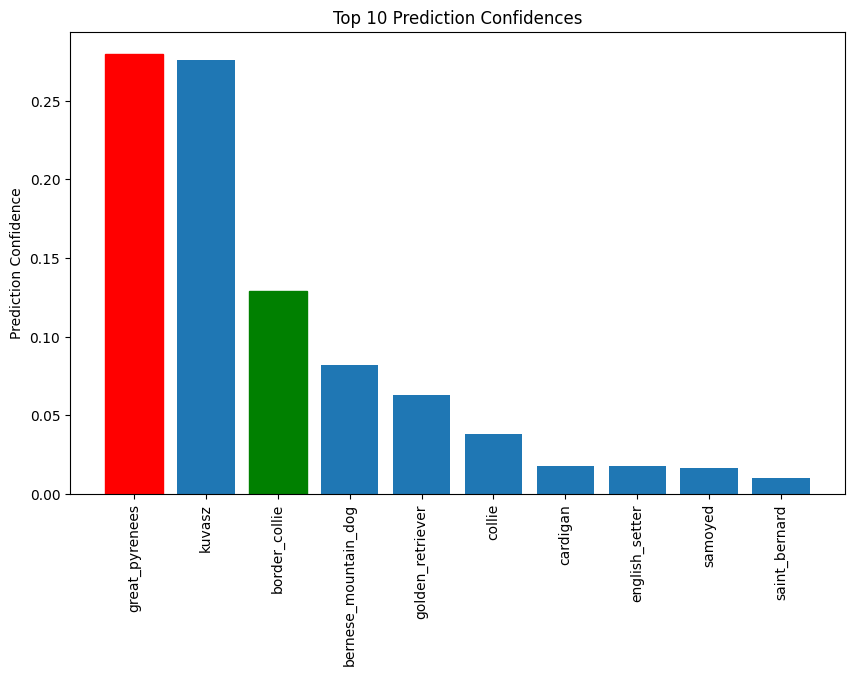

<Figure size 640x480 with 0 Axes>

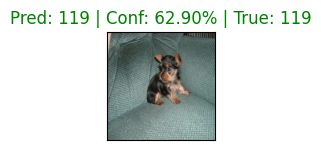

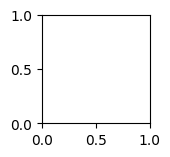

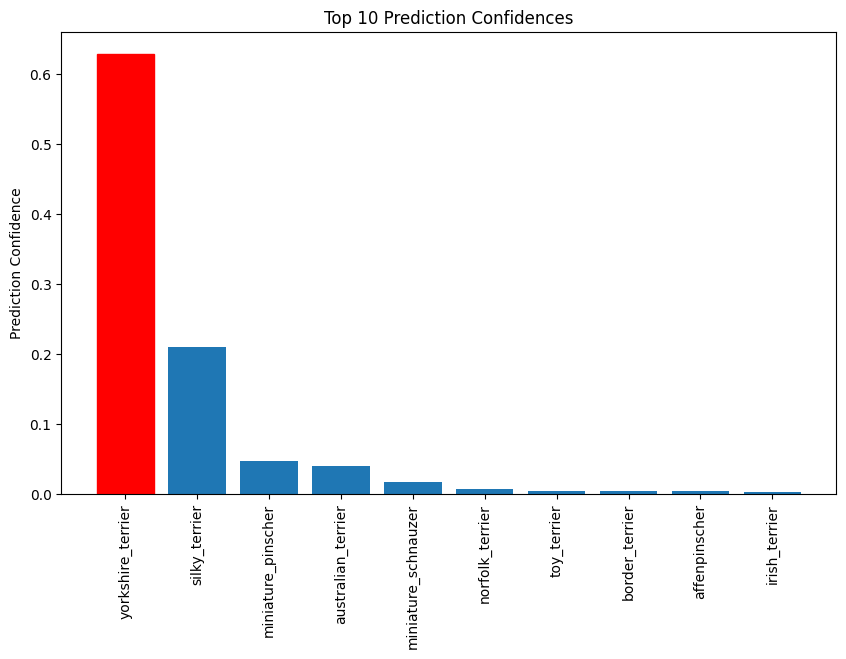

<Figure size 640x480 with 0 Axes>

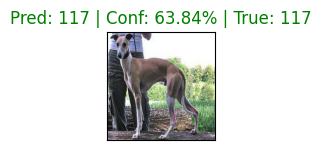

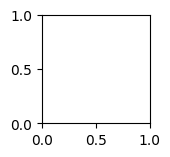

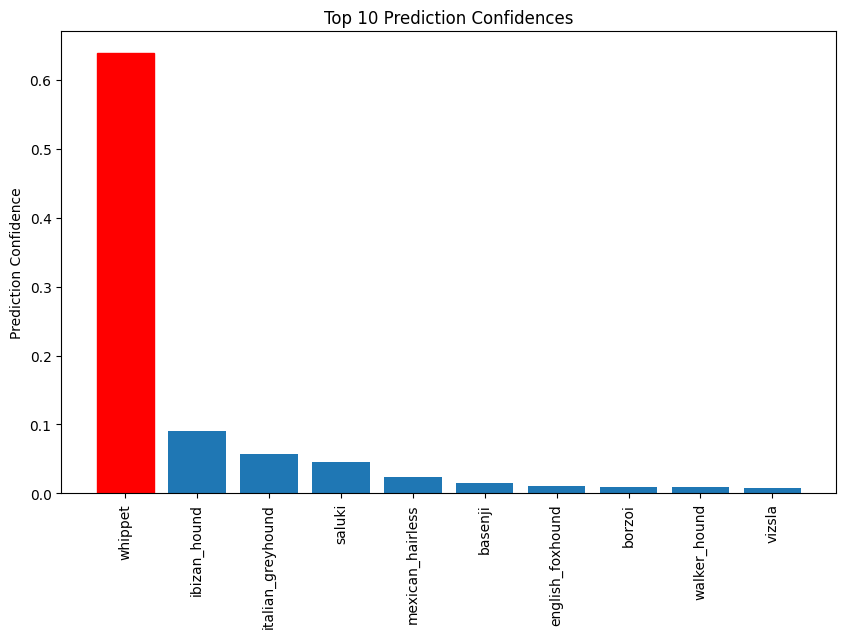

<Figure size 640x480 with 0 Axes>

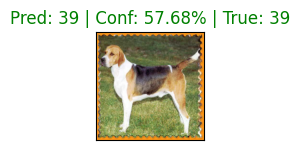

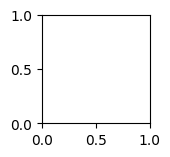

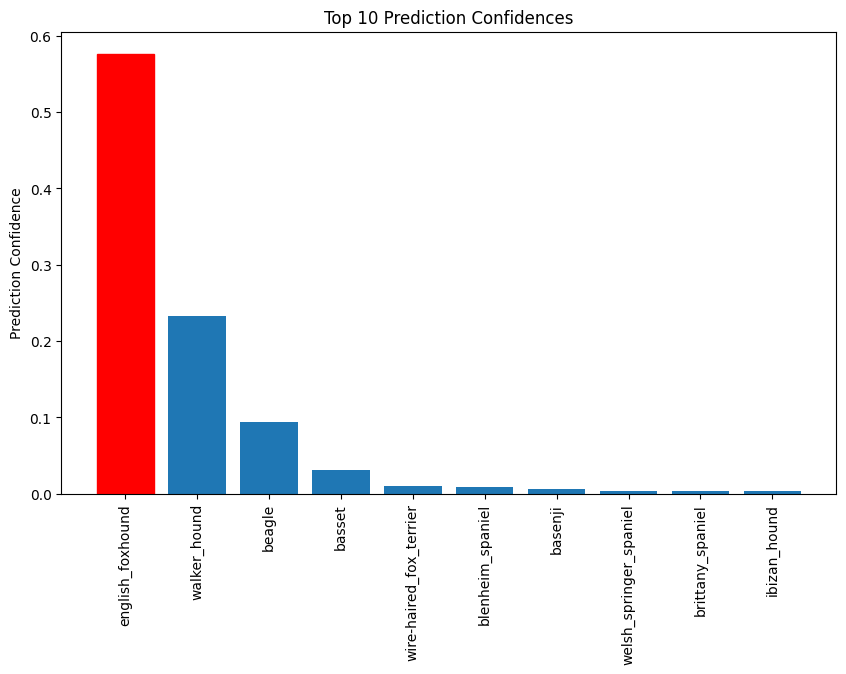

<Figure size 640x480 with 0 Axes>

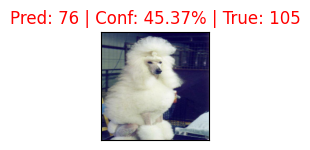

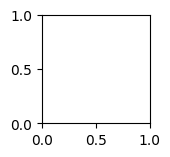

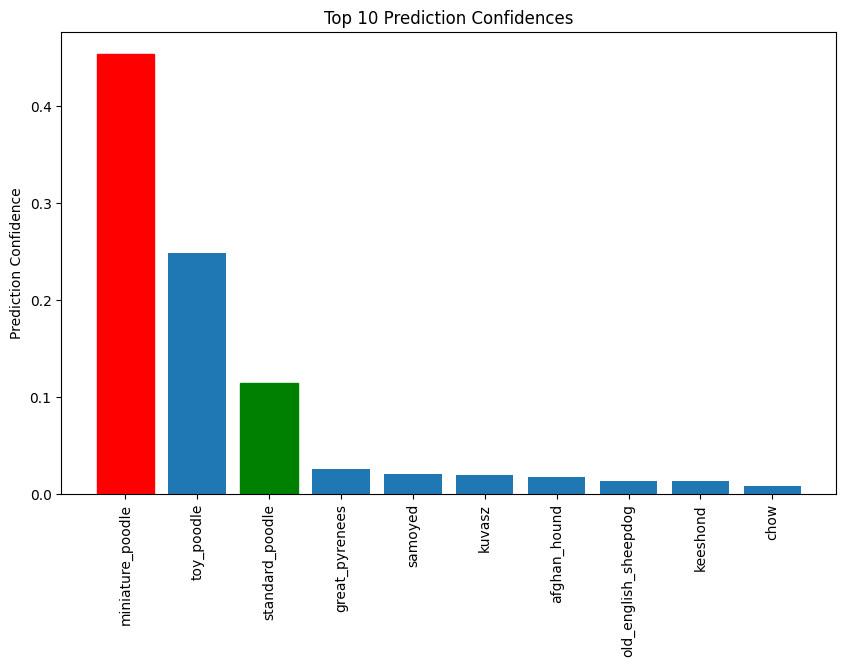

<Figure size 640x480 with 0 Axes>

In [ ]:
# Let's check out a few predictions and their different values
i_multiplier = 10
num_rows = 3
num_cols = 2
num_images = num_rows*num_cols
plt.figure(figsize=(10*num_cols, 5*num_rows))
for i in range(num_images):
  plt.subplot(num_rows, 2*num_cols, 2*i+1)
  plot_pred(prediction_probabilities=predictions,
            labels = val_labels,
            images = val_images,
            n=i+i_multiplier)
  plt.subplot(num_rows , 2*num_cols , 2*i+2)
  plot_pred_conf(prediction_probabilities=predictions,
                labels=val_labels,
                n=i+i_multiplier)
  plt.tight_layout(h_pad=1.0)
  plt.show()


**Challange:** How would you create a confusion matrix with our models with our models predictions and truth labels?

## Saving and reloading a trained model

In [ ]:
import os
import datetime

def save_model(model, suffix=None):
    """
    Save a given model in the models directory and append a suffix (string).
    Uses modern .keras format (recommended).
    """

    # Proper timestamp
    timestamp = datetime.datetime.now().strftime("%Y%m%d-%H%M%S")

    modeldir = "/content/drive/My Drive/Dog Vision/models"

    model_path = os.path.join(
        modeldir,
        f"{timestamp}-{suffix}.keras"
    )

    print(f"Saving model to: {model_path}...")

    model.save(model_path)   # modern format

    return model_path

In [ ]:
def load_model(model_path):
    print(f"Loading saved model from: {model_path}")

    model = tf_keras.models.load_model(
        model_path,
        custom_objects={"KerasLayer": hub.KerasLayer}
    )

    return model

Now we've got functions to save and load a trained model, let's make sure they work!

In [ ]:
# Save our model trained on 1000 images
save_model(model, suffix="1000-images-mobilenetv2-adam")

Saving model to: /content/drive/My Drive/Dog Vision/models/20260521-052148-1000-images-mobilenetv2-adam.keras...


'/content/drive/My Drive/Dog Vision/models/20260521-052148-1000-images-mobilenetv2-adam.keras'

In [ ]:
# Load a trained model
loaded_1000_image_model = load_model('/content/drive/My Drive/Dog Vision/models/20260223-181636-1000-images-mobilenetv2-adam.keras')

Loading saved model from: /content/drive/My Drive/Dog Vision/models/20260223-181636-1000-images-mobilenetv2-adam.keras


In [ ]:
# Evaluate the pre-saved model
model.evaluate(val_data)

7/7 [==============================] - 1s 84ms/step - loss: 1.1734 - accuracy: 0.7300


[1.1733587980270386, 0.7300000190734863]

In [ ]:
#Evaluate the loaded model
loaded_1000_image_model.evaluate(val_data)

7/7 [==============================] - 1s 99ms/step - loss: 1.1434 - accuracy: 0.7250


[1.1434321403503418, 0.7250000238418579]

## Trainning  a bing dog model(on the full data )

In [ ]:
len(x),len(y)

(10222, 10222)

In [ ]:
#Create a data batch with the full data set
full_data = create_data_batches(x, y)

Creating training data batches...


In [ ]:
full_data

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 120), dtype=tf.bool, name=None))>

In [ ]:
# Create a model for full model
full_model = create_model()

In [ ]:
# Create full model callback
full_model_tensoreboard = create_tensorboard_callback()
# No validation set when training on all the data, so we can't moniter validation accuracy
full_model_early_stopping = tf.keras.callbacks.EarlyStopping(monitor="accuracy",
                                                             patience=3)

**Note:** Running the cell below will take a little while (maybe upto 30 minutes for the first epoch)because the GPU we're using in the runtime has to load all of the images into memory.

In [ ]:
# fit the full model to full data
full_model.fit(x=full_data,
               epochs=NUM_EPOCHS,
               callbacks=[full_model_tensoreboard, full_model_early_stopping])


Epoch 1/100
 48/320 [===>..........................] - ETA: 54:19 - loss: 3.5126 - accuracy: 0.2611

In [ ]:
save_model(full_model, suffix="full-data-mobilenetv2-adam")

In [ ]:
# Load in the full model
loaded_full_model = load_model("/content/drive/My Drive/Dog Vision/models/20260223-184052-full-data-mobilenetv2-adam.keras")

## Making prediction on the test dataset

since our model has been trained on the images in the foem of tensor batches, to make predictions in the test data, we'll have to get it into the same formate.

Luckliy we created `create_data_batches() ` earlier which can take a list of filenames as input and conver them into tensor batches.

To make prediction on the test data, we'll:
* Get the test image filenames
* Conver the filename into test data batches using`create_data_batches()` and setting the`Test_data`peremeter to `true` (since the test data dosen't have labels).
* Make a presentatios array by passing the test batches to the `predict()` method called on our model

In [ ]:
# loded  test image filename
test_path = '/content/drive/My Drive/Dog Vision/test'

test_filenames = [
    os.path.join(test_path, fname)
    for fname in os.listdir(test_path)
]

test_filenames[:10]

In [ ]:
# Create test data batch
test_data = create_data_batches(test_filenames, test_data=True)

In [ ]:
# Make predictions on test data batch using the loaded full model
test_predictions = loaded_full_model.predict(test_data,
                                              verbose=1)

In [ ]:
# to save the test prediction
np.savetxt(
    "/content/drive/My Drive/Dog Vision/test_prediction.csv",
    test_predictions,
    delimiter=","
)

In [ ]:
# load predictions (numpy array) from csv file
test_predictions = np.loadtxt("/content/drive/My Drive/Dog Vision/test_prediction.csv", delimiter=",")

In [ ]:
test_predictions[:10]

In [ ]:
test_predictions.shape

## Prepareing test dataset predictions keggle

looking at the kaggle sample submission, we find that it wants our models prediction probability output in a DataFrame with an ID and a column for each diffrent dog breed.
https://www.kaggle.com/c/dog-breed-identification/overview/evaluation

To get the data in this format, we'll:
* Create a pandas DataFrame with an ID colaumn as well as a column for each dog breed
* Add data (the prediction probalistites ) to each of the dog breed columns
* Export the DataFrame as a CSV to submit it to Kaggle.

In [ ]:
# Create a pandas DataFrame with empty columns
preds_df = pd.DataFrame(columns=["id"]+ list(unique_breed))
preds_df.head()

In [ ]:
test_path

In [ ]:
# Append test image ID's to predictions DataFrame
test_ids = [os.path.splitext(path) for path in os.listdir(test_path)]
preds_df["id"] = test_ids

In [ ]:
# Add the prediction probabilities to each dog breed column
preds_df.loc[:, list(unique_breed)] = test_predictions

In [ ]:
# Save our predictions dataframe to CSV for submission to Kaggle
preds_df.to_csv("/content/drive/My Drive/Dog Vision/full_model_predictions_submission.csv", index=False)

## Making prediction on coustom images

To make predictions on custom images, we'll:
* Get the filepaths of our images.
* Turn the filePath into batches using `create_data_batches()`.And since our custom images won't have labels, we set the `test_data`parameter to `True`.
* Pass the custom image data batch to our model's `predict()`method.
* Convert the prediction output probabiltites to predictions labels.

In [ ]:
# custom images
custom_path = "/content/drive/My Drive/Dog Vision/custom_images/"
custom_image_paths = [custom_path + fname for fname in os.listdir(custom_path)]

In [ ]:
custom_image_paths

['/content/drive/My Drive/Dog Vision/custom_images/IMG-20260225-WA0002.jpg',
 '/content/drive/My Drive/Dog Vision/custom_images/IMG-20260225-WA0003.jpg',
 '/content/drive/My Drive/Dog Vision/custom_images/IMG-20260225-WA0001.jpg']

In [ ]:
# Turn custom images into batch datasets
custom_data = create_data_batches(custom_image_paths, test_data=True)
custom_data

Creating test data batches...


<_PrefetchDataset element_spec=TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None)>

In [ ]:
# make predictions on the custom data
custom_preds = loaded_full_model.predict(custom_data)

NameError: name 'loaded_full_model' is not defined

In [ ]:
# Get custom image prediction labels
custom_pred_labels = [get_pred_label(custom_preds[i]) for i in range(len(custom_preds))]
custom_pred_labels

NameError: name 'custom_preds' is not defined

In [ ]:
# get custom images (our unbatchify () function wan't work since these aren't lables ... maybe we could fix this later)
custom_images = []
# Loop through unbatched data
for image in custom_data.unbatch().as_numpy_iterator():
  custom_images.append(image)

In [ ]:
# Check custom image predection
plt.figure(figsize=(10, 10))
for i, image in enumerate(custom_images):
  plt.subplot(1, 3, i+1)
  plt.xticks([])
  plt.yticks([])
  plt.title(custom_pred_labels[i])
  plt.imshow(image)